# 03 – Splits and models

**Part A – Splits (Step 3)**
- A1: main dataset (14 core leagues) and extra test sets
- A2: checks on the time-based split
- A3: time split vs random 80/20 rows vs random 80/20 by player

**Part B – Models (Step 4)**
- B1: tuning and fitting protocol
- B2: baselines (naive, Ridge) and tree models (RF, XGBoost, LightGBM, CatBoost)
- B3: GRU over the valuation history (PyTorch on the M2 GPU, "MPS")
- B4: test results
- B5: extra test sets: new leagues, OTHER, UNKNOWN
- B6: training with and without the unknown-club rows
- B7: save predictions and models

**Training target:** every model predicts the **12-month log change** (`y − log_value`). Adding back `log_value` gives the predicted log value, and its exponential gives euros.

**Metrics**
- *On the change:* MAE_change and R²_change. MAE_change is equal to the MAE of the log value.
- *Ranking:*
  - Spearman correlation between predicted and real 12-month change.
  - **Top-10% precision:** of the 10% of players with the largest predicted rise, the % whose value really rose. The same is computed for the 10% largest predicted falls.
- *On the final value in euros:* MAE_eur, median absolute % error (MdAPE), and % of players predicted within ±20%.
- Every table includes the **naive "no change" baseline**. It predicts the same change (zero) for everyone, so its ranking metrics are undefined (shown as empty).
- The skill column is the share of the naive error that a model removes: `skill = 1 − MAE_change(model) / MAE_change(naive)`.
- R² on the *value level* appears only in appendix table A1 (see B4).

In [1]:
import sys, os, json, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
from src.config import (RESULTS, PROCESSED, SEED, TRAIN_END, VAL_END, set_seed, savefig,
                        apply_plot_style, PALETTE, TEXT_SECONDARY)
from src.features import FEATURES, CATEGORICAL
from src.data import load_dataset, main_and_extra, core_plus_unknown, random_split, player_group_split, xy
from src.metrics import evaluate_frame, table, base_rates, HEADLINE
from src import models as M

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import lightgbm as lgb, torch

set_seed(SEED)
apply_plot_style()
pd.set_option("display.width", 170, "display.max_columns", 30)
MODEL_DIR = ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

_progress = os.environ.get("NB_PROGRESS_LOG")
def log(*args):
    msg = " ".join(str(a) for a in args)
    print(msg)
    if _progress:
        with open(_progress, "a") as fh:
            fh.write(time.strftime("%H:%M:%S ") + msg + "\n")

## A1. Main dataset and extra test sets

> *For the paper – rule for the 14 core leagues:* A league is a **core league** if the source data contain its first-division matches for the whole study period. Concretely, its first match in `games.csv` must be before 1 January 2013 (the 2012/13 season).
> - The rule uses only **data coverage** and was fixed **before any model was trained or evaluated** (see notebook 02, section 3).
> - All 14 leagues that pass are covered from 2012/13 to 2025/26.
> - The other 17 leagues appear only from July 2024. They form an extra **"new leagues"** test set.

In [2]:
full = load_dataset()
main, extra = main_and_extra(full)
CORE = sorted(main["league_t"].astype(str).unique().tolist())
print(f"14 core leagues: {CORE}")

order = ["train", "val", "test"]
def summary(d):
    return pd.Series({"rows": len(d), "players": d.player_id.nunique(), "first_t": d.t.min(),
                      "last_t": d.t.max(), "last_target": d.target_date.max()})
sizes = pd.DataFrame({s: summary(main[main.split == s]) for s in order}).T
sizes.loc["  of which train with target < 2023-07-01 (tuning)"] = summary(main[main.train_target_before_val])
sizes.loc["extra test: new leagues (17)"] = summary(extra[extra.league_group == "new_leagues"])
sizes.loc["extra test: OTHER (known club, uncovered league)"] = summary(extra[extra.league_group == "OTHER"])
sizes.loc["extra test: UNKNOWN club"] = summary(extra[extra.league_group == "UNKNOWN"])
sizes.to_csv(RESULTS / "table07_main_split_sizes.csv")
sizes

14 core leagues: ['BE1', 'DK1', 'ES1', 'FR1', 'GB1', 'GR1', 'IT1', 'L1', 'NL1', 'PO1', 'RU1', 'SC1', 'TR1', 'UKR1']


,rows,players,first_t,last_t,last_target
train,112775,17938,2014-07-01 00:00:00,2023-06-30 00:00:00,2024-06-30 00:00:00
val,11711,5450,2023-07-01 00:00:00,2024-06-30 00:00:00,2025-07-18 00:00:00
test,12167,6292,2024-07-01 00:00:00,2025-07-11 00:00:00,2026-06-11 00:00:00
of which train with target < 2023-07-01 (tuning),99976,16601,2014-07-01 00:00:00,2022-08-19 00:00:00,2023-06-30 00:00:00
extra test: new leagues (17),8671,5608,2024-07-22 00:00:00,2025-07-18 00:00:00,2026-06-11 00:00:00
"extra test: OTHER (known club, uncovered league)",15079,9308,2024-07-01 00:00:00,2025-07-28 00:00:00,2026-06-12 00:00:00
extra test: UNKNOWN club,59,41,2024-09-23 00:00:00,2025-06-27 00:00:00,2026-06-09 00:00:00


## A2. Checks on the time-based split

- The three periods do not overlap, and **no training target date falls in the test period**.
- Players *can* appear in both train and test, at different times. This is realistic: in practice we forecast players whose past we already know.

In [3]:
tr, va, te = (main[main.split == s] for s in order)
checks = pd.Series({
    "train t < val t": tr.t.max() < va.t.min(),
    "val t < test t": va.t.max() < te.t.min(),
    "all train targets before test period": tr.target_date.max() < pd.Timestamp(VAL_END),
    "tuning rows: targets before validation period":
        tr.loc[tr.train_target_before_val, "target_date"].max() < pd.Timestamp(TRAIN_END),
    "no duplicate (player, t) rows": not main.duplicated(["player_id", "t"]).any(),
})
assert checks.all()
display(checks.to_frame("passed"))
print(f"test rows whose player also appears in train: {te.player_id.isin(tr.player_id).mean():.1%}")

,passed
train t < val t,True
val t < test t,True
all train targets before test period,True
tuning rows: targets before validation period,True
"no duplicate (player, t) rows",True


test rows whose player also appears in train: 70.2%


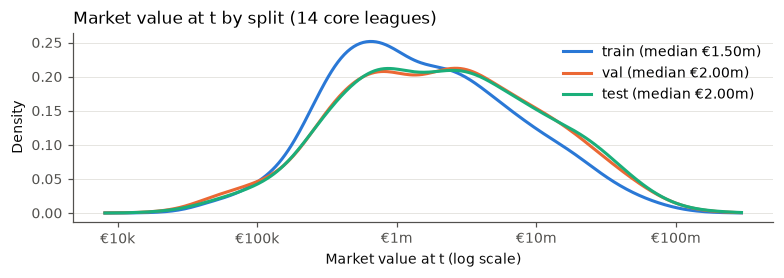

In [4]:
from scipy.stats import gaussian_kde
fig, ax = plt.subplots(figsize=(7.2, 2.6))
grid = np.linspace(9, 19.5, 400)
for i, s in enumerate(order):
    d = main.loc[main.split == s, "log_value"].astype(float)
    kde = gaussian_kde(d, bw_method=0.25)        # smooth curve; values are rounded (€1m, €2m ...)
    ax.plot(grid, kde(grid), color=PALETTE[i], label=f"{s} (median €{np.exp(d.median()) / 1e6:.2f}m)")
ticks = [1e4, 1e5, 1e6, 1e7, 1e8]
ax.set_xticks(np.log(ticks), ["€10k", "€100k", "€1m", "€10m", "€100m"])
ax.set_xlabel("Market value at t (log scale)")
ax.set_ylabel("Density")
ax.set_title("Market value at t by split (14 core leagues)", loc="left")
ax.legend(loc="upper right")
fig.tight_layout()
savefig(fig, "fig03_value_distribution_by_split")
plt.show()

## A3. Time split vs random 80/20 (rows) vs random 80/20 (by player)

We train the **same model** on the same 136k core rows under three splitting schemes:

| scheme | how rows are split | what the model can see from the "future" |
|---|---|---|
| **Time split** (ours) | train t < 2023-07, test t ≥ 2024-07 | nothing |
| **Random rows** | each row randomly 80/20 | other periods **and** later rows of the *same* player |
| **Random by player** | `GroupShuffleSplit` on `player_id`, 80/20 | other periods, but never the same player |

- Comparing **random rows vs random by player** shows the effect of *repeated players*.
- Comparing **random by player vs time split** shows the effect of *mixing time periods*.
- **Model:** LightGBM with fixed, untuned settings, identical in all three schemes.
- The test sets cover different years. So we also score both random schemes **only on their test rows from the test period** (t ≥ 2024-07-01).

In [5]:
LGB_FIXED = dict(n_estimators=600, learning_rate=0.05, num_leaves=63, min_child_samples=40,
                 subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                 random_state=SEED, deterministic=True, force_row_wise=True, verbose=-1)

def fit_predict_fixed(train_df, test_df):
    X, d = xy(train_df)
    model = lgb.LGBMRegressor(**LGB_FIXED).fit(X, d)
    return test_df["log_value"].to_numpy() + model.predict(xy(test_df)[0])

rs, ps = random_split(main), player_group_split(main)
schemes = {
    "Time split": (main.split == "train", main.split == "test"),
    "Random 80/20 (rows)": (rs == "train", rs == "test"),
    "Random 80/20 (by player)": (ps == "train", ps == "test"),
}
rows, split_preds = {}, []
for name, (m_tr, m_te) in schemes.items():
    test_df = main[m_te]
    pred = fit_predict_fixed(main[m_tr], test_df)
    split_preds.append(test_df[["player_id", "t", "y", "log_value"]].assign(scheme=name, pred_LightGBM=pred))
    recent = (test_df["t"] >= VAL_END).to_numpy()
    for subset, mask in [("all test rows", np.ones(len(test_df), bool)), ("test rows with t ≥ 2024-07", recent)]:
        if name == "Time split" and subset != "all test rows":
            continue
        d = test_df[mask]
        rows[(name, subset, "Naive (no change)")] = evaluate_frame(d, d["log_value"])
        rows[(name, subset, "LightGBM (untuned)")] = evaluate_frame(d, pred[mask])

split_cmp = table(rows)
split_cmp.index.names = ["scheme", "test rows", "model"]
naive = split_cmp.xs("Naive (no change)", level="model")["MAE_change"]
split_cmp["skill_vs_naive_%"] = [round(100 * (1 - r.MAE_change / naive[(s, sub)]), 1)
                                 for (s, sub, _), r in split_cmp.iterrows()]
split_cmp.to_csv(RESULTS / "table08_random_vs_time_split.csv")
pd.concat(split_preds, ignore_index=True).to_parquet(PROCESSED / "predictions_split_comparison.parquet", index=False)
split_cmp[HEADLINE + ["skill_vs_naive_%"]]

n  MAE_change  R2_change  Spearman_change  top10_rise_prec_%  top10_fall_prec_%    MAE_eur  \
scheme                   test rows                  model                                                                                                                
Time split               all test rows              Naive (no change)   12167      0.4800    -0.0004              NaN                NaN                NaN  2886942.0   
                                                    LightGBM (untuned)  12167      0.3981     0.3641           0.5788              71.08              95.23  2469637.0   
Random 80/20 (rows)      all test rows              Naive (no change)   27266      0.4476    -0.0004              NaN                NaN                NaN  2037539.0   
                                                    LightGBM (untuned)  27266      0.3594     0.4010           0.6108              76.42              91.82  1655124.0   
                         test rows with t ≥ 2024-07 Naive (no change)    2472      0.4885    -0.0009              NaN                NaN                NaN  2880714.0   
                                                    LightGBM (untuned)   2472      0.3722     0.4526           0.6664              78.23              96.37  2233785.0   
Random 80/20 (by player) all test rows              Naive (no change)   27268      0.4524    -0.0000              NaN                NaN                NaN  2105490.0   
                                                    LightGBM (untuned)  27268      0.3733     0.3689           0.5815              75.50              91.13  1777835.0   
                         test rows with t ≥ 2024-07 Naive (no change)    2512      0.5021    -0.0048              NaN                NaN                NaN  3165994.0   
                                                    LightGBM (untuned)   2512      0.4030     0.3887           0.6143              80.56              96.03  2639071.0   

                                                                        MdAPE_%  within_20%  skill_vs_naive_%  
scheme                   test rows                  model                                                      
Time split               all test rows              Naive (no change)     37.50       32.20               0.0  
                                                    LightGBM (untuned)    29.04       36.37              17.1  
Random 80/20 (rows)      all test rows              Naive (no change)     33.33       34.99               0.0  
                                                    LightGBM (untuned)    26.41       39.62              19.7  
                         test rows with t ≥ 2024-07 Naive (no change)     37.50       31.67               0.0  
                                                    LightGBM (untuned)    26.89       38.92              23.8  
Random 80/20 (by player) all test rows              Naive (no change)     33.33       34.57               0.0  
                                                    LightGBM (untuned)    27.31       38.49              17.5  
                         test rows with t ≥ 2024-07 Naive (no change)     40.00       30.61               0.0  
                                                    LightGBM (untuned)    29.09       36.66              19.7

### Why does a random split look better? Measuring the leak

With a random row split, a test row at date *t* often has **training rows of the same player from after *t***. Sometimes the exact valuation we are asked to predict appears in training as another row's `log_value`. A player-grouped split removes this.

In [6]:
def leak_stats(train_df, test_df):
    later = (test_df[["player_id", "t"]].reset_index()
             .merge(train_df[["player_id", "t"]].rename(columns={"t": "t_train"}), on="player_id"))
    has_later = later[later.t_train > later.t]["index"].unique()
    exact = test_df[["player_id", "target_date"]].reset_index().merge(
        train_df[["player_id", "t"]], left_on=["player_id", "target_date"], right_on=["player_id", "t"])
    return {"test rows": len(test_df),
            "player has a LATER row in train (%)": 100 * len(has_later) / len(test_df),
            "target valuation is a train row's input (%)": 100 * exact["index"].nunique() / len(test_df),
            "test rows dated after train start (%)": 100 * (test_df.t > train_df.t.min()).mean()}

leak = pd.DataFrame({n: leak_stats(main[a], main[b]) for n, (a, b) in schemes.items()}).T.round(1)
leak.to_csv(RESULTS / "table09_random_split_leak_mechanism.csv")
leak

,test rows,player has a LATER row in train (%),target valuation is a train row's input (%),test rows dated after train start (%)
Time split,12167.0,0.0,0.0,100.0
Random 80/20 (rows),27266.0,82.0,46.9,99.7
Random 80/20 (by player),27268.0,0.0,0.0,99.7


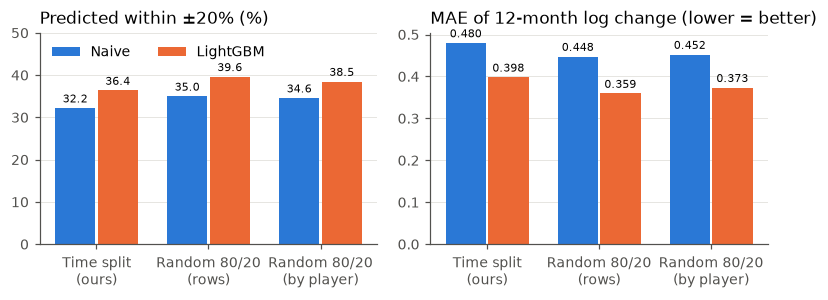

In [7]:
plot = split_cmp.xs("all test rows", level="test rows").reset_index()
short = {"Time split": "Time split\n(ours)", "Random 80/20 (rows)": "Random 80/20\n(rows)",
         "Random 80/20 (by player)": "Random 80/20\n(by player)"}
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.8))
for ax, metric, title, fmt in [(axes[0], "within_20%", "Predicted within ±20% (%)", "%.1f"),
                               (axes[1], "MAE_change", "MAE of 12-month log change (lower = better)", "%.3f")]:
    x = np.arange(len(short))
    for j, (mname, label) in enumerate([("Naive (no change)", "Naive"), ("LightGBM (untuned)", "LightGBM")]):
        vals = plot[plot.model == mname].set_index("scheme").loc[list(short), metric]
        bars = ax.bar(x + (j - 0.5) * 0.38, vals, width=0.36, color=PALETTE[j], label=label)
        ax.bar_label(bars, fmt=fmt, fontsize=7, padding=2)
    ax.set_xticks(x, list(short.values()))
    ax.set_title(title, loc="left")
axes[0].set_ylim(0, 50)
axes[0].legend(loc="upper left", ncols=2)
fig.tight_layout()
savefig(fig, "fig04_random_vs_time_split")
plt.show()

# Part B – Models (Step 4)

## B1. Protocol

1. **Tuning:** fit on train rows whose target date is before the validation period (99,976 rows). Score each setting on the validation split (11,711 rows) by MAE_change. This is "light" tuning: 6–15 settings per model, chosen at random from a small grid with a fixed seed. The grids were widened once wherever the best validation setting sat at the edge of the grid (decided on validation scores only).
2. **Final fit:** refit the best setting on **all** train rows (112,775 rows; every target is before the test period). Boosting models keep the number of trees found by early stopping in step 1.
3. **Test:** evaluate once on the test split (12,167 rows).

> *For the Method section – why validation rows are not used for the final model:* Each validation row (valuation date between July 2023 and June 2024) has a target about 12 months later, i.e. between mid-2024 and mid-2025. That is inside the test period. A model trained on these rows would learn from market values recorded during the test period, so it would partly "see" the period it is evaluated on. We therefore use the validation rows only to choose settings, and train the final models on the training rows alone. Every final training target is dated before 1 July 2024, the start of the test period.

In [8]:
tune_df = main[main.train_target_before_val].reset_index(drop=True)
final_df = main[main.split == "train"].reset_index(drop=True)
val_df = main[main.split == "val"].reset_index(drop=True)
test_df = main[main.split == "test"].reset_index(drop=True)
print(f"tuning fit: {len(tune_df):,} | final fit: {len(final_df):,} | validation: {len(val_df):,} | test: {len(test_df):,}")

# predictions on the log-value scale, per model, for test / val / extra
P_test, P_val, P_extra = {}, {}, {}
P_test["Naive (no change)"] = test_df["log_value"].to_numpy()
P_val["Naive (no change)"] = val_df["log_value"].to_numpy()
P_extra["Naive (no change)"] = extra["log_value"].to_numpy()

tuning fit: 99,976 | final fit: 112,775 | validation: 11,711 | test: 12,167


## B2. Baselines and tree models

| model | settings tried | notes |
|---|---|---|
| Ridge regression | 6 | linear baseline; missing values → median + 0/1 flag; one-hot categories; standardised |
| Random Forest | 9 | 300 trees, each on a 50% sample; same encoding without scaling |
| LightGBM | 15 | native categories; early stopping on validation |
| XGBoost | 10 | `tree_method="hist"`, native categories; early stopping |
| CatBoost | 9 | native categories; early stopping |

Every setting tried is saved to `results/table11_tuning_log.csv`, so the tuning can be reported in full.

In [9]:
fitted, best_params, tuning_logs = {}, {}, []
for spec in M.MODELS:
    t0 = time.time()
    log(f"== {spec.name}")
    model, params, n_trees, tlog = M.tune_and_fit(spec, tune_df, val_df, final_df, log=log)
    fitted[spec.name] = model
    best_params[spec.name] = {**params, "n_trees": n_trees}
    tuning_logs.append(tlog)
    P_test[spec.name] = test_df["log_value"].to_numpy() + model.predict(xy(test_df)[0])
    P_extra[spec.name] = extra["log_value"].to_numpy() + model.predict(xy(extra)[0])
    log(f"   best {params} trees={n_trees} | total {time.time() - t0:.0f}s")

tuning_log = pd.concat(tuning_logs, ignore_index=True)
tuning_log.to_csv(RESULTS / "table11_tuning_log.csv", index=False)
val_best = tuning_log.loc[tuning_log.groupby("model", sort=False)["val_MAE_change"].idxmin(),
                          ["model", "n_trees", "val_MAE_change", "seconds"]]
display(val_best.set_index("model"))

== Ridge regression


  Ridge regression {'alpha': 1}  trees=None  val MAE=0.4020  (1s)


  Ridge regression {'alpha': 10}  trees=None  val MAE=0.4019  (1s)


  Ridge regression {'alpha': 100}  trees=None  val MAE=0.4011  (1s)


  Ridge regression {'alpha': 1000}  trees=None  val MAE=0.4003  (1s)


...

  CatBoost         {'depth': 6, 'l2_leaf_reg': 10, 'loss_function': 'RMSE'}  trees=587  val MAE=0.3920  (15s)


  CatBoost         {'depth': 6, 'l2_leaf_reg': 30, 'loss_function': 'MAE'}  trees=444  val MAE=0.3891  (15s)


  CatBoost         {'depth': 8, 'l2_leaf_reg': 3, 'loss_function': 'RMSE'}  trees=372  val MAE=0.3925  (17s)


   best {'depth': 6, 'l2_leaf_reg': 3, 'loss_function': 'MAE'} trees=764 | total 184s


,n_trees,val_MAE_change,seconds
model,,,
Ridge regression,None,0.400329,0.7
Random Forest,None,0.394251,24.5
LightGBM,596,0.388870,6.0
XGBoost,532,0.389526,6.4
CatBoost,764,0.388533,23.3


## B3. GRU over the valuation history (PyTorch, Apple GPU)

- **Sequence branch:** the player's last **10 valuations** on/before *t*, oldest first. Each step has: log value relative to the value at *t*, years before *t*, and a 0/1 "real step" flag. Shorter histories are padded on the left. Only valuations dated ≤ *t* are used.
- **Dense branch:** the same 50 tabular features, encoded as for Ridge.
- **Head:** the two branches are joined, then 2 dense layers predict the 12-month log change. Loss: SmoothL1.
- **Protocol:**
  - Seed 0 is trained on the tuning rows with early stopping on validation; this picks the number of epochs.
  - Then **3 seeds** are trained on all train rows for that many epochs.
  - We report the mean ± standard deviation over the seeds. The GPU is not fully deterministic, so small differences between runs are expected.

In [10]:
vals_hist = pd.read_parquet(PROCESSED / "player_valuations.parquet",
                            columns=["player_id", "date", "market_value_in_eur"])
device = "mps" if torch.backends.mps.is_available() else "cpu"
log(f"GRU device: {device}")

def gru_inputs(enc, d):
    X, chg = xy(d)
    return M.build_sequences(d, vals_hist), enc.transform(X).astype("float32"), chg.to_numpy("float32")

enc_tune = M.tabular_encoder(scale=True).fit(xy(tune_df)[0])
S_tu, T_tu, Y_tu = gru_inputs(enc_tune, tune_df)
S_va, T_va, Y_va = gru_inputs(enc_tune, val_df)
t0 = time.time()
_, best_epoch, curve = M.train_gru(S_tu, T_tu, Y_tu, seed=SEED, epochs=30,
                                   seq_val=S_va, tab_val=T_va, y_val=Y_va)
log(f"GRU tuning: best epoch {best_epoch}, val MAE {min(curve):.4f} ({time.time() - t0:.0f}s)")

enc = M.tabular_encoder(scale=True).fit(xy(final_df)[0])
S_fi, T_fi, Y_fi = gru_inputs(enc, final_df)
S_te, T_te, _ = gru_inputs(enc, test_df)
S_ex, T_ex, _ = gru_inputs(enc, extra)
SEEDS = [SEED, SEED + 1, SEED + 2]
def mean_metrics(d, preds):      # mean of every metric over several predictions (e.g. 3 GRU seeds)
    return pd.DataFrame([evaluate_frame(d, p) for p in preds]).mean().to_dict()

gru_test, gru_extra, gru_seed_rows = [], [], {}
for seed in SEEDS:
    t0 = time.time()
    net = M.train_gru(S_fi, T_fi, Y_fi, seed=seed, epochs=best_epoch)
    p = test_df["log_value"].to_numpy() + M.predict_gru(net, S_te, T_te)
    gru_test.append(p)
    gru_extra.append(extra["log_value"].to_numpy() + M.predict_gru(net, S_ex, T_ex))
    gru_seed_rows[f"seed {seed}"] = evaluate_frame(test_df, p)
    log(f"GRU seed {seed}: test MAE_change {gru_seed_rows[f'seed {seed}']['MAE_change']:.4f} ({time.time() - t0:.0f}s)")

gru_seeds = table(gru_seed_rows)
gru_seeds.loc["mean"] = gru_seeds.mean()
gru_seeds.loc["std"] = gru_seeds.iloc[:3].std()
gru_seeds.to_csv(RESULTS / "table12_gru_seeds.csv")
best_params["GRU"] = {"epochs": int(best_epoch), "seq_len": M.SEQ_LEN, "hidden": 32, "seeds": 3}
P_val["GRU"] = None
display(gru_seeds[HEADLINE].round(4))

GRU device: mps


GRU tuning: best epoch 9, val MAE 0.3893 (15s)


GRU seed 42: test MAE_change 0.4005 (9s)


GRU seed 43: test MAE_change 0.3947 (8s)


GRU seed 44: test MAE_change 0.3967 (8s)


,n,MAE_change,R2_change,Spearman_change,top10_rise_prec_%,top10_fall_prec_%,MAE_eur,MdAPE_%,within_20%
seed 42,12167.0,0.4005,0.3368,0.5603,72.7200,93.2600,2.516528e+06,28.9400,36.9100
seed 43,12167.0,0.3947,0.3347,0.5784,73.3800,93.1800,2.460555e+06,27.7700,38.1300
seed 44,12167.0,0.3967,0.3332,0.5714,71.8200,93.9200,2.452548e+06,27.8800,38.2300
mean,12167.0,0.3973,0.3349,0.5700,72.6400,93.4533,2.476544e+06,28.1967,37.7567
std,0.0,0.0029,0.0018,0.0091,0.7831,0.4061,3.485812e+04,0.6461,0.7349


## B4. Test results – 14 core leagues

- **One row per model.** The GRU row is the **mean of the 3 seeds' metrics**; its spread is in `table12_gru_seeds.csv`.
- **Quick check – LightGBM + GRU average:** the plain mean of the two models' predicted log values, computed for each GRU seed and then averaged. It has no extra tuning.
- **Headline metrics** are shown below. The full set (RMSE, MAPE) is in `table13_test_results_core.csv`.
- **Appendix table A1 – value-level R²:** R² on the log value is high (about 0.88) for *every* model, even the naive one. This is mainly because a player's value next year is close to this year's value, so it says little about forecasting skill. The main tables therefore use the change scale.

In [11]:
rows = {name: evaluate_frame(test_df, p) for name, p in P_test.items()}
rows["GRU (mean of 3 seeds)"] = mean_metrics(test_df, gru_test)
ensembles = [0.5 * (P_test["LightGBM"] + p) for p in gru_test]
rows["LightGBM + GRU average"] = mean_metrics(test_df, ensembles)
res_full = table(rows, naive_key="Naive (no change)", appendix=True)
res_full[["n", "R2_log", "R2_change"]].rename(columns={"R2_log": "R2_value_level", "R2_change": "R2_change (main text)"}) \
    .to_csv(RESULTS / "tableA1_value_level_r2.csv")
res = res_full.drop(columns="R2_log")
res["val_MAE_change"] = (val_best.set_index("model")["val_MAE_change"].reindex(res.index).round(4))
res.loc["GRU (mean of 3 seeds)", "val_MAE_change"] = round(min(curve), 4)
res.loc["Naive (no change)", "val_MAE_change"] = round(float(np.mean(np.abs(val_df["y"] - val_df["log_value"]))), 4)
res.to_csv(RESULTS / "table13_test_results_core.csv")
ens_seeds = table({f"seed {s}": evaluate_frame(test_df, p) for s, p in zip(SEEDS, ensembles)})
print("LightGBM + GRU average, per GRU seed: MAE_change",
      ens_seeds["MAE_change"].round(4).tolist(), "| within ±20%", ens_seeds["within_20%"].round(2).tolist())
print("Base rates on the test set (%):", {k: round(v, 1) for k, v in base_rates(test_df).items()})
with open(RESULTS / "best_params.json", "w") as fh:
    json.dump(best_params, fh, indent=2, default=str)
display(res[HEADLINE + ["skill_vs_naive_%", "val_MAE_change"]])
print("Appendix A1 (value-level R²):")
res_full[["R2_log"]].T

LightGBM + GRU average, per GRU seed: MAE_change [0.3942, 0.3921, 0.3929] | within ±20% [37.59, 38.03, 38.26]
Base rates on the test set (%): {'rose_%': 35.4, 'unchanged_%': 13.0, 'fell_%': 51.5}


,n,MAE_change,R2_change,Spearman_change,top10_rise_prec_%,top10_fall_prec_%,MAE_eur,MdAPE_%,within_20%,skill_vs_naive_%,val_MAE_change
Naive (no change),12167,0.4800,-0.0004,NaN,NaN,NaN,2886942.0,37.50,32.20,0.0,0.4619
Ridge regression,12167,0.4075,0.3240,0.5640,68.78,90.63,2506840.0,30.49,35.05,15.1,0.4003
Random Forest,12167,0.4001,0.3587,0.5862,69.76,96.55,2460834.0,29.48,35.75,16.6,0.3943
LightGBM,12167,0.3940,0.3337,0.5849,73.05,95.56,2446458.0,28.12,37.80,17.9,0.3889
XGBoost,12167,0.3950,0.3458,0.5831,71.65,95.15,2466674.0,28.47,37.28,17.7,0.3895
CatBoost,12167,0.3948,0.3356,0.5838,72.14,95.65,2441098.0,28.05,37.60,17.7,0.3885
GRU (mean of 3 seeds),12167,0.3973,0.3349,0.5700,72.64,93.45,2476544.0,28.20,37.76,17.2,0.3893
LightGBM + GRU average,12167,0.3931,0.3423,0.5865,73.40,95.02,2442211.0,27.81,37.96,18.1,NaN


Appendix A1 (value-level R²):


,Naive (no change),Ridge regression,Random Forest,LightGBM,XGBoost,CatBoost,GRU (mean of 3 seeds),LightGBM + GRU average
R2_log,0.828,0.8838,0.8897,0.8854,0.8875,0.8858,0.8856,0.8869


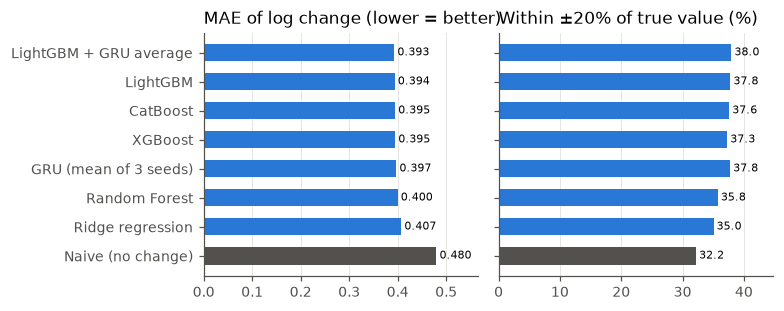

In [12]:
plot = res.drop(columns="val_MAE_change").sort_values("MAE_change", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.9), sharey=True)
colors = [TEXT_SECONDARY if n.startswith("Naive") else PALETTE[0] for n in plot.index]
for ax, metric, title, fmt in [(axes[0], "MAE_change", "MAE of log change (lower = better)", "%.3f"),
                               (axes[1], "within_20%", "Within ±20% of true value (%)", "%.1f")]:
    bars = ax.barh(plot.index, plot[metric], color=colors, height=0.6)
    ax.bar_label(bars, fmt=fmt, fontsize=7, padding=2)
    ax.set_title(title, loc="left")
    ax.grid(axis="x", color="#e4e3df", linewidth=0.6)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, plot[metric].max() * 1.18)
fig.tight_layout()
savefig(fig, "fig05_test_results_core")
plt.show()

## B5. Extra test sets (same models, trained on the 14 core leagues only)

- **new leagues (17):** these leagues are not in the training data at all. Match statistics exist only from 2024/25, so most performance windows are incomplete.
- **OTHER:** the club is known but plays outside the covered leagues (mostly second divisions), so there are no match statistics.
- **UNKNOWN:** the club at *t* is unknown. There are very few such rows in the test period (see notebook 02, section 4b).

In [13]:
ex_rows = {}
for grp, d in extra.groupby("league_group", observed=True):
    idx = d.index.to_numpy()
    for name, p in P_extra.items():
        ex_rows[(grp, name)] = evaluate_frame(d, p[idx])
    ex_rows[(grp, "GRU (mean of 3 seeds)")] = mean_metrics(d, [p[idx] for p in gru_extra])
extra_res = table(ex_rows)
extra_res.index.names = ["test set", "model"]
naive = extra_res.xs("Naive (no change)", level="model")["MAE_change"]
extra_res["skill_vs_naive_%"] = [round(100 * (1 - r.MAE_change / naive[g]), 1) for (g, _), r in extra_res.iterrows()]
extra_res = extra_res.rename(index={"new_leagues": "new leagues (17)"}, level=0)
extra_res.to_csv(RESULTS / "table14_test_results_extra.csv")
extra_res[HEADLINE + ["skill_vs_naive_%"]]

n  MAE_change  R2_change  Spearman_change  top10_rise_prec_%  top10_fall_prec_%   MAE_eur  MdAPE_%  within_20%  \
test set         model                                                                                                                                       
OTHER            Naive (no change)      15079      0.5059    -0.0607              NaN                NaN                NaN  620870.0    33.33       35.05   
                 Ridge regression       15079      0.4673     0.2405           0.4925              75.33              74.73  603928.0    34.95       31.22   
                 Random Forest          15079      0.4431     0.2589           0.5237              72.02              89.32  566984.0    31.25       35.43   
                 LightGBM               15079      0.4444     0.2374           0.5105              74.80              89.59  573881.0    30.48       35.88   
                 XGBoost                15079      0.4492     0.2389           0.5193              73.41              89.85  573737.0    32.13       34.03   
                 CatBoost               15079      0.4513     0.2096           0.4878              73.87              85.88  573013.0    30.83       35.43   
                 GRU (mean of 3 seeds)  15079      0.4669     0.2048           0.4513              71.53              78.14  594358.0    33.89       32.60   
UNKNOWN          Naive (no change)         59      0.8575    -0.4105              NaN                NaN                NaN  368051.0    50.00       25.42   
                 Ridge regression          59      0.7263     0.0234           0.3279              66.67               0.00  356870.0    45.64       28.81   
                 Random Forest             59      0.7953    -0.1867           0.1785             100.00               0.00  367727.0    47.85       23.73   
                 LightGBM                  59      0.7519    -0.1226           0.2948              83.33              16.67  360435.0    48.31       32.20   
                 XGBoost                   59      0.7123     0.0583           0.3284              83.33              16.67  351964.0    44.92       25.42   
                 CatBoost                  59      0.7668    -0.1632           0.2911              83.33              16.67  362569.0    47.58       27.12   
                 GRU (mean of 3 seeds)     59      0.8678    -0.3846           0.2766              72.22              22.22  370448.0    49.96       19.77   
new leagues (17) Naive (no change)       8671      0.4476    -0.0013              NaN                NaN                NaN  662871.0    33.33       33.55   
                 Ridge regression        8671      0.4202     0.2112           0.4880              66.47              84.22  629116.0    31.15       33.71   
                 Random Forest           8671      0.3982     0.2656           0.5255              64.86              95.51  597175.0    29.53       36.93   
                 LightGBM                8671      0.3880     0.2627           0.5274              68.43              97.12  583187.0    27.01       39.06   
                 XGBoost                 8671      0.3931     0.2540           0.5252              66.59              95.05  581325.0    28.98       37.52   
                 CatBoost                8671      0.4003     0.2375           0.4813              68.20              93.43  601684.0    28.80       36.51   
                 GRU (mean of 3 seeds)   8671      0.4070     0.2207           0.4745              68.63              88.02  604623.0    30.49       35.58   

                                        skill_vs_naive_%  
test set         model                                    
OTHER            Naive (no change)                   0.0  
                 Ridge regression                    7.6  
                 Random Forest                      12.4  
                 LightGBM                           12.2  
                 XGBoost                            11.

## B6. Training with and without the unknown-club rows

- **Without:** the main models, trained on core-league rows only.
- **With:** the same model and settings, retrained on core rows **plus** unknown-club rows (`league_t = "UNKNOWN"`, `club_known = 0`). This adds about 76k training rows.

We use the model with the best validation score and test both versions on: the core test set, the core + unknown-club test set, and the unknown-club test rows alone (few rows).

In [14]:
tree_models = ["Random Forest", "LightGBM", "XGBoost", "CatBoost"]
best_tree = min(tree_models, key=lambda n: val_best.set_index("model").loc[n, "val_MAE_change"])
spec = {s.name: s for s in M.MODELS}[best_tree]
log(f"B6 uses {best_tree} (best validation score among tree models)")

plus = core_plus_unknown(full)
plus_train = plus[plus.split == "train"]
p = {k: v for k, v in best_params[best_tree].items() if k != "n_trees"}
t0 = time.time()
m_plus = spec()
m_plus.fit(p, *xy(plus_train), n_trees=best_params[best_tree]["n_trees"])
log(f"refit on core + unknown ({len(plus_train):,} rows) in {time.time() - t0:.0f}s")

unk_test = extra[extra.league_group == "UNKNOWN"]
both_test = pd.concat([test_df, unk_test], ignore_index=True)
sets = {"core test": test_df, "core + unknown-club test": both_test, "unknown-club test only": unk_test}
v_rows = {}
for set_name, d in sets.items():
    X = xy(d)[0]
    v_rows[(set_name, "Naive (no change)")] = evaluate_frame(d, d["log_value"])
    v_rows[(set_name, f"{best_tree} trained WITHOUT unknown-club rows")] = evaluate_frame(d, d["log_value"].to_numpy() + fitted[best_tree].predict(X))
    v_rows[(set_name, f"{best_tree} trained WITH unknown-club rows")] = evaluate_frame(d, d["log_value"].to_numpy() + m_plus.predict(X))
unk_res = table(v_rows)
unk_res.index.names = ["test set", "model"]
naive = unk_res.xs("Naive (no change)", level="model")["MAE_change"]
unk_res["skill_vs_naive_%"] = [round(100 * (1 - r.MAE_change / naive[s]), 1) for (s, _), r in unk_res.iterrows()]
unk_res.to_csv(RESULTS / "table15_with_without_unknown_club.csv")
unk_res[HEADLINE + ["skill_vs_naive_%"]]

B6 uses CatBoost (best validation score among tree models)


refit on core + unknown (188,744 rows) in 33s


n  MAE_change  R2_change  Spearman_change  top10_rise_prec_%  top10_fall_prec_%    MAE_eur  \
test set                 model                                                                                                                                        
core test                Naive (no change)                           12167      0.4800    -0.0004              NaN                NaN                NaN  2886942.0   
                         CatBoost trained WITHOUT unknown-club rows  12167      0.3948     0.3356           0.5838              72.14              95.65  2441098.0   
                         CatBoost trained WITH unknown-club rows     12167      0.3948     0.3328           0.5864              71.49              95.56  2433930.0   
core + unknown-club test Naive (no change)                           12226      0.4818    -0.0006              NaN                NaN                NaN  2874787.0   
                         CatBoost trained WITHOUT unknown-club rows  12226      0.3966     0.3330           0.5839              72.20              95.67  2431068.0   
                         CatBoost trained WITH unknown-club rows     12226      0.3964     0.3314           0.5868              71.63              95.50  2423911.0   
unknown-club test only   Naive (no change)                              59      0.8575    -0.4105              NaN                NaN                NaN   368051.0   
                         CatBoost trained WITHOUT unknown-club rows     59      0.7668    -0.1632           0.2911              83.33              16.67   362569.0   
                         CatBoost trained WITH unknown-club rows        59      0.7266    -0.0601           0.4919             100.00               0.00   357815.0   

                                                                     MdAPE_%  within_20%  skill_vs_naive_%  
test set                 model                                                                              
core test                Naive (no change)                             37.50       32.20               0.0  
                         CatBoost trained WITHOUT unknown-club rows    28.05       37.60              17.8  
                         CatBoost trained WITH unknown-club rows       28.09       37.92              17.8  
core + unknown-club test Naive (no change)                             37.50       32.17               0.0  
                         CatBoost trained WITHOUT unknown-club rows    28.14       37.55              17.7  
                         CatBoost trained WITH unknown-club rows       28.10       37.91              17.7  
unknown-club test only   Naive (no change)                             50.00       25.42               0.0  
                         CatBoost trained WITHOUT unknown-club rows    47.58       27.12              10.6  
                         CatBoost trained WITH unknown-club rows       41.47       35.59              15.3

## B7. Save predictions and models (used in notebook 04)

- `data/processed/predictions_test.parquet`: one row per test row (core + extra), with a column per model holding the predicted log value. The GRU has one column per seed.
- `data/processed/predictions_split_comparison.parquet`: the A3 predictions, used for the bootstrap in notebook 04.
- `models/`: the fitted boosting models, small files that are needed for SHAP. Random Forest and Ridge are not saved, because they are quick to refit.

In [15]:
keep = ["player_id", "t", "league_group", "league_t", "position", "sub_position", "age", "value_t",
        "log_value", "y", "value_target", "target_date"]
pt = test_df[keep].copy()
pe = extra[keep].copy()
for name, p in P_test.items():
    pt[f"pred_{name}"] = p
for name, p in P_extra.items():
    pe[f"pred_{name}"] = p
for s, p_t, p_e in zip(SEEDS, gru_test, gru_extra):
    pt[f"pred_GRU seed{s}"], pe[f"pred_GRU seed{s}"] = p_t, p_e
pt["test_set"], pe["test_set"] = "core", pe["league_group"].astype(str)
preds = pd.concat([pt, pe], ignore_index=True)
preds.columns = [c.replace(" (no change)", "").replace(" ", "_") for c in preds.columns]
preds.to_parquet(PROCESSED / "predictions_test.parquet", index=False)

fitted["LightGBM"].m.booster_.save_model(str(MODEL_DIR / "lightgbm.txt"))
fitted["XGBoost"].m.save_model(str(MODEL_DIR / "xgboost.json"))
fitted["CatBoost"].m.save_model(str(MODEL_DIR / "catboost.cbm"))
print(f"saved predictions: {len(preds):,} rows; models:", sorted(p.name for p in MODEL_DIR.iterdir()))

saved predictions: 35,976 rows; models: ['catboost.cbm', 'lightgbm.txt', 'xgboost.json']


### Part B – summary
See the chat summary. The tables in `results/` (07–15) and the figures `fig04`–`fig05` hold every number.